# Sentiment Analysis Using Machine Learning

## Client’s business case and dataset
### - ABC Restaurant intends to build a binary classification model (positive/negative) for customer reviews received on their Facebook page. 
### - Business intends to build an inhouse customer support team to call-back customers who gave negative feedbacks, and resolve their issues/complaints, ensuring they revisit. 
### - Restaurant has shared following datasets: 
### - Historical reviews – along with labels 
### - Fresh reviews – without labels 

### Importing libraries

In [18]:
import pandas as pd
import numpy as np
import re    # regualr expression
import nltk  # natural language toolkit
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import joblib
import pickle

[nltk_data] Downloading package stopwords to C:\Users\Renu
[nltk_data]     R\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### Importing dataset

In [19]:
dataset = pd.read_csv('data/historical_reviews.tsv', delimiter = '\t', quoting = 3)

In [20]:
dataset.shape

(900, 2)

In [21]:
dataset.head()

,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1


### Data cleaning

In [22]:
ps = PorterStemmer()

all_stopwords = stopwords.words('english')
all_stopwords.remove('not')

In [23]:
corpus = []  #for storing customer reviews post data cleaning

for i in range(0,900): 
    review = re.sub('[^a-zA-Z]',' ',dataset['Review'][i]) #d ropping special characters and numbers
    review = review.lower() # converting to lower case
    review = review.split()
    review = [ps.stem(word) for word in review if not word in set(all_stopwords)]
    review = ' '.join(review)
    corpus.append(review)

In [24]:
corpus

['wow love place',
 'crust not good',
 'not tasti textur nasti',
 'stop late may bank holiday rick steve recommend love',
 'select menu great price',
 'get angri want damn pho',
 'honeslti tast fresh',
 'potato like rubber could tell made ahead time kept warmer',
 'fri great',
 'great touch',
 'servic prompt',
 'would not go back',
 'cashier care ever say still end wayyy overpr',
 'tri cape cod ravoli chicken cranberri mmmm',
 'disgust pretti sure human hair',
 'shock sign indic cash',
 'highli recommend',
 'waitress littl slow servic',
 'place not worth time let alon vega',
 'not like',
 'burritto blah',
 'food amaz',
 'servic also cute',
 'could care less interior beauti',
 'perform',
 'right red velvet cake ohhh stuff good',
 'never brought salad ask',
 'hole wall great mexican street taco friendli staff',
 'took hour get food tabl restaur food luke warm sever run around like total overwhelm',
 'worst salmon sashimi',
 'also combo like burger fri beer decent deal',
 'like final blow

### Dividing dataset into training and test set

In [25]:
Y = dataset.iloc[:,-1].values
# Split the data first
X_train_text, X_test_text, Y_train, Y_test = train_test_split(
    corpus,
    Y,
    test_size=0.20,
    random_state=42,
    stratify=Y
)

### Data Transformation

In [26]:
# Create Bag of Words
cv = CountVectorizer(max_features=1420)

# Fit ONLY on training reviews
X_train = cv.fit_transform(X_train_text).toarray()

# Transform test reviews using the same vocabulary
X_test = cv.transform(X_test_text).toarray()

### Saving bag of words(bow) dictionary tolater use in prediction

In [27]:
bow_path = 'sentiment_analysis_bow'
pickle.dump(cv, open(bow_path,"wb"))

### Model Training and Comparison

In [28]:
models = {
    'Multinomial Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Linear SVM': LinearSVC(random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

In [29]:
results = []

for name, model in models.items():

    model.fit(X_train, Y_train)

    Y_pred = model.predict(X_test)

    accuracy = accuracy_score(Y_test, Y_pred)
    precision = precision_score(Y_test, Y_pred)
    recall = recall_score(Y_test, Y_pred)
    f1 = f1_score(Y_test, Y_pred)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

In [30]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
2,Linear SVM,0.816667,0.823529,0.848485,0.835821
0,Multinomial Naive Bayes,0.783333,0.767857,0.868687,0.815166
1,Logistic Regression,0.788889,0.801980,0.818182,0.810000
3,Random Forest,0.805556,0.880952,0.747475,0.808743


In [31]:
best_model_name = results_df.iloc[0]['Model']

print("Best Model:", best_model_name)

Best Model: Linear SVM


In [32]:
best_model = models[best_model_name]

Y_pred_best = best_model.predict(X_test)

print("Best Model:", best_model_name)

print("\nClassification Report:")
print(classification_report(Y_test, Y_pred_best))

print("\nConfusion Matrix:")
print(confusion_matrix(Y_test, Y_pred_best))

Best Model: Linear SVM

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.78      0.79        81
           1       0.82      0.85      0.84        99

    accuracy                           0.82       180
   macro avg       0.82      0.81      0.81       180
weighted avg       0.82      0.82      0.82       180


Confusion Matrix:
[[63 18]
 [15 84]]


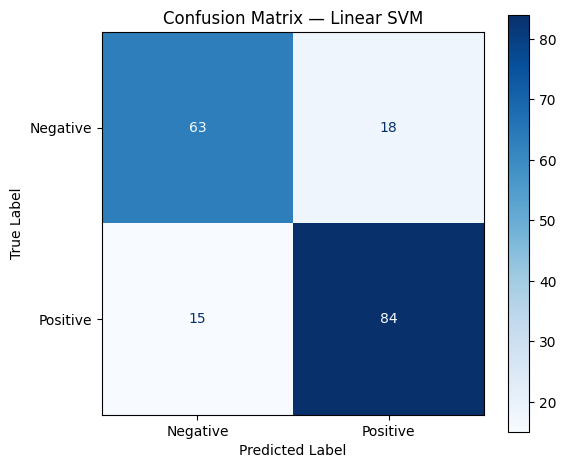

In [33]:
cm = confusion_matrix(Y_test, Y_pred_best)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax, values_format="d")

plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [34]:
# exporting NB Classifier to later use in prediction
joblib.dump(best_model, 'sentiment_analysis_model')
with open('model_info', 'w') as f:
    f.write(best_model_name)